# Đánh giá mô hình LightGBM phát hiện URL phishing — Hybrid-Guard

Notebook này đánh giá mô hình **LightGBM** đã huấn luyện (`artifacts/lgb_final/url_phishing_model.joblib`) theo cách trình bày thường gặp trong các bài nghiên cứu: bảng chỉ số kèm **khoảng tin cậy 95% (bootstrap)**, các đường cong ROC/PR, phân tích ngưỡng, hiệu chuẩn xác suất, độ quan trọng đặc trưng (gain/split, SHAP), **kiểm định chéo k-fold**, learning curve và **so sánh có kiểm định thống kê** với Random Forest và Decision Tree.

Notebook chỉ đọc model và dataset, không sửa artifact nào. Hình (PNG 300 dpi + PDF) và bảng (CSV + LaTeX) được lưu vào `artifacts/report/lgb_research/`.

**Nội dung**
1. Thiết lập và cấu hình
2. Mô hình và siêu tham số
3. Mô tả dữ liệu
4. Tái lập tập kiểm tra (hold-out)
5. Chỉ số tổng hợp + khoảng tin cậy 95%
6. Ma trận nhầm lẫn
7. Đường cong ROC và Precision–Recall
8. Phân tích ngưỡng quyết định
9. Hiệu chuẩn xác suất (calibration)
10. Phân phối điểm và thống kê KS
11. Độ quan trọng đặc trưng và SHAP
12. Kiểm định chéo phân tầng k-fold
13. Learning curve
14. So sánh với RF / DT (McNemar + paired bootstrap)
15. Phân tích lỗi
16. Xuất kết quả và tóm tắt

> Yêu cầu thêm ngoài `requirements.txt`: `pip install matplotlib seaborn shap ipykernel` (SHAP là tuỳ chọn). Các bước tốn thời gian (CV, learning curve, SHAP) bật/tắt được trong ô cấu hình.

## 1. Thiết lập và cấu hình

In [2]:
import json
import os
import platform
import sys
import time
import warnings
from pathlib import Path

import joblib
import lightgbm
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import Markdown, display
from lightgbm import LGBMClassifier
from scipy import stats
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    classification_report,
    cohen_kappa_score,
    confusion_matrix,
    f1_score,
    log_loss,
    matthews_corrcoef,
    precision_recall_curve,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import StratifiedKFold, train_test_split

warnings.filterwarnings("ignore", category=UserWarning)

# Tìm thư mục gốc dự án (chứa url_ml/) để import được code của Hybrid-Guard.
PROJECT_ROOT = Path.cwd().resolve()
while not (PROJECT_ROOT / "url_ml").exists() and PROJECT_ROOT != PROJECT_ROOT.parent:
    PROJECT_ROOT = PROJECT_ROOT.parent
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from train_url_model import ensure_features, resolve_data_path
from url_ml.feature_engineering import NUMERIC_FEATURES
from webapp.app.config import MALICIOUS_THRESHOLD, SUSPICIOUS_THRESHOLD

print(f"Project root : {PROJECT_ROOT}")
print(f"Python       : {platform.python_version()}")
print(f"LightGBM     : {lightgbm.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"pandas       : {pd.__version__} | numpy {np.__version__} | matplotlib {matplotlib.__version__}")

Project root : D:\GITproject\Hybrid-Guard
Python       : 3.11.6
LightGBM     : 4.7.0
scikit-learn : 1.9.1
pandas       : 3.0.5 | numpy 2.4.6 | matplotlib 3.11.2


In [5]:
# ===================== CẤU HÌNH =====================
DATA_PATH = "Dataset.csv"  
LABEL_COL = "label"
LGB_MODEL_PATH = PROJECT_ROOT / "artifacts/lgb_final/url_phishing_model.joblib"
BASELINE_MODEL_PATHS = {
    "Random Forest": PROJECT_ROOT / "artifacts/rf_final/url_phishing_model.joblib",
    "Decision Tree": PROJECT_ROOT / "artifacts/dt_final/url_phishing_model.joblib",
}

TEST_SIZE = 0.2            # giống mặc định của train_url_model.py
DECISION_THRESHOLD = 0.5   # ngưỡng phân lớp nhị phân của mô hình

N_BOOTSTRAP = 1000         # số lần lấy mẫu bootstrap cho khoảng tin cậy 95%
N_BOOTSTRAP_COMPARE = 300  # bootstrap ghép cặp khi so sánh mô hình
RUN_CV = True              # huấn luyện lại LightGBM trên k fold (tốn vài phút)
CV_FOLDS = 5
RUN_LEARNING_CURVE = True
RUN_SHAP = True
SHAP_SAMPLE_SIZE = 5000

REPORT_DIR = PROJECT_ROOT / "artifacts/report/lgb_research"
REPORT_DIR.mkdir(parents=True, exist_ok=True)
TABLES = {}  # các bảng sẽ được xuất ở mục 16

CLASS_NAMES = ["Benign", "Malicious"]
COLORS = {
    "LightGBM": "#1f77b4",
    "Random Forest": "#2ca02c",
    "Decision Tree": "#d62728",
    "Benign": "#4c72b0",
    "Malicious": "#dd8452",
}

sns.set_theme(style="whitegrid", context="paper")
plt.rcParams.update(
    {
        "font.family": "serif",
        "font.size": 10,
        "axes.titlesize": 11,
        "axes.labelsize": 10,
        "legend.fontsize": 9,
        "figure.dpi": 110,
        "savefig.dpi": 300,
        "savefig.bbox": "tight",
        "grid.alpha": 0.35,
    }
)


def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(REPORT_DIR / f"{name}.{ext}")


print(f"Kết quả sẽ lưu tại: {REPORT_DIR}")

Kết quả sẽ lưu tại: D:\GITproject\Hybrid-Guard\artifacts\report\lgb_research


In [6]:
def metrics_from_arrays(y_true, y_pred, y_score, eps=1e-15):
    """Tính các chỉ số phân lớp nhị phân (nhanh, dùng được cho bootstrap)."""
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    y_score = np.asarray(y_score, dtype=float)

    tn, fp, fn, tp = np.bincount(y_true * 2 + y_pred, minlength=4).astype(float)
    n = tn + fp + fn + tp
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    specificity = tn / (tn + fp) if tn + fp else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    mcc_den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
    accuracy = (tp + tn) / n
    p_e = ((tp + fp) * (tp + fn) + (fn + tn) * (fp + tn)) / n**2
    p = np.clip(y_score, eps, 1 - eps)

    return {
        "Accuracy": accuracy,
        "Balanced Accuracy": (recall + specificity) / 2,
        "Precision": precision,
        "Recall (TPR)": recall,
        "Specificity (TNR)": specificity,
        "F1-score": f1,
        "MCC": (tp * tn - fp * fn) / mcc_den if mcc_den else 0.0,
        "Cohen's Kappa": (accuracy - p_e) / (1 - p_e) if p_e < 1 else 0.0,
        "ROC-AUC": roc_auc_score(y_true, y_score),
        "PR-AUC (AP)": average_precision_score(y_true, y_score),
        "Log Loss": float(-np.mean(y_true * np.log(p) + (1 - y_true) * np.log(1 - p))),
        "Brier Score": float(np.mean((y_score - y_true) ** 2)),
        "FPR": fp / (fp + tn) if fp + tn else 0.0,
        "FNR": fn / (fn + tp) if fn + tp else 0.0,
    }


LOWER_IS_BETTER = {"Log Loss", "Brier Score", "FPR", "FNR"}


def bootstrap_metrics(y_true, y_pred, y_score, n_boot, seed):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    rows = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        rows.append(metrics_from_arrays(y_true[idx], y_pred[idx], y_score[idx]))
    return pd.DataFrame(rows)


def mean_std(series, digits=4):
    return f"{series.mean():.{digits}f} ± {series.std(ddof=1):.{digits}f}"

## 2. Mô hình và siêu tham số

Tải artifact LightGBM và liệt kê siêu tham số (thường là *Table: Hyperparameters* trong bài báo). `random_state` lấy từ artifact để tái lập đúng phép chia train/test lúc huấn luyện.

In [7]:
artifact = joblib.load(LGB_MODEL_PATH)
lgb_model = artifact["model"]
feature_names = list(artifact["feature_names"])
training_info = artifact.get("training", {}) or {}
RANDOM_STATE = int(training_info.get("random_state", 42))
assert feature_names == list(NUMERIC_FEATURES), "Thứ tự đặc trưng trong artifact khác NUMERIC_FEATURES"

params = lgb_model.get_params()
hyperparams = pd.DataFrame(
    [
        ("Thuật toán", "LightGBM (Gradient Boosting Decision Tree)"),
        ("n_estimators", params["n_estimators"]),
        ("Số cây thực tế", lgb_model.booster_.num_trees()),
        ("learning_rate", params["learning_rate"]),
        ("num_leaves", params["num_leaves"]),
        ("max_depth", params["max_depth"]),
        ("class_weight", params["class_weight"]),
        ("boosting_type", params["boosting_type"]),
        ("random_state", params["random_state"]),
        ("Số đặc trưng", len(feature_names)),
        ("Kích thước artifact (MB)", round(LGB_MODEL_PATH.stat().st_size / 2**20, 2)),
    ],
    columns=["Tham số", "Giá trị"],
)
hyperparams["Giá trị"] = hyperparams["Giá trị"].astype(str)
TABLES["table_hyperparameters"] = hyperparams
display(hyperparams)

,Tham số,Giá trị
0,Thuật toán,LightGBM (Gradient Boosting Decision Tree)
1,n_estimators,300
2,Số cây thực tế,300
3,learning_rate,0.05
4,num_leaves,63
5,max_depth,-1
6,class_weight,balanced
7,boosting_type,gbdt
8,random_state,42
9,Số đặc trưng,22


## 3. Mô tả dữ liệu

Bảng 1 mô tả quy mô và phân bố nhãn. Bảng 2 so sánh giá trị trung bình của từng đặc trưng giữa hai lớp, kèm **Cohen's d** (độ lớn hiệu ứng) để thấy đặc trưng nào tách hai lớp rõ nhất.

In [8]:
data_path = resolve_data_path(DATA_PATH)
t0 = time.perf_counter()
df = pd.read_csv(data_path, low_memory=False)
df = ensure_features(df.copy())
df = df.dropna(subset=[LABEL_COL])  # giống train_url_model.py
print(f"Đọc {data_path} ({data_path.stat().st_size / 2**20:.1f} MB) trong {time.perf_counter() - t0:.1f}s")

X = df[NUMERIC_FEATURES].astype(float)
y = df[LABEL_COL].astype(int).to_numpy()

n_total = len(df)
n_pos = int(y.sum())
dataset_summary = pd.DataFrame(
    [
        ("Tổng số URL", f"{n_total:,}"),
        ("Benign (0)", f"{n_total - n_pos:,} ({(n_total - n_pos) / n_total:.2%})"),
        ("Malicious (1)", f"{n_pos:,} ({n_pos / n_total:.2%})"),
        ("Số đặc trưng lexical", len(NUMERIC_FEATURES)),
        ("URL trùng lặp", f"{int(df['url'].duplicated().sum()):,}" if "url" in df else "N/A"),
        ("Giá trị thiếu trong đặc trưng", int(X.isna().sum().sum())),
    ],
    columns=["Thuộc tính", "Giá trị"],
)
TABLES["table1_dataset"] = dataset_summary
display(Markdown("**Bảng 1.** Thống kê tập dữ liệu"))
display(dataset_summary)

Đọc Dataset.csv.csv (147.8 MB) trong 3.6s


**Bảng 1.** Thống kê tập dữ liệu

,Thuộc tính,Giá trị
0,Tổng số URL,"716,627"
1,Benign (0),"429,976 (60.00%)"
2,Malicious (1),"286,651 (40.00%)"
3,Số đặc trưng lexical,22
4,URL trùng lặp,7
5,Giá trị thiếu trong đặc trưng,0


In [9]:
benign, malicious = X[y == 0], X[y == 1]
pooled_std = np.sqrt((benign.var(ddof=1) + malicious.var(ddof=1)) / 2).replace(0, np.nan)
feature_stats = pd.DataFrame(
    {
        "Benign mean": benign.mean(),
        "Benign std": benign.std(ddof=1),
        "Malicious mean": malicious.mean(),
        "Malicious std": malicious.std(ddof=1),
        "Cohen's d": (malicious.mean() - benign.mean()) / pooled_std,
    }
)
feature_stats = feature_stats.reindex(feature_stats["Cohen's d"].abs().sort_values(ascending=False).index)
feature_stats.index.name = "Feature"
TABLES["table2_feature_stats"] = feature_stats.reset_index()
display(Markdown("**Bảng 2.** Thống kê đặc trưng theo lớp (sắp xếp theo |Cohen's d|)"))
display(feature_stats.round(4))

**Bảng 2.** Thống kê đặc trưng theo lớp (sắp xếp theo |Cohen's d|)

,Benign mean,Benign std,Malicious mean,Malicious std,Cohen's d
Feature,,,,,
is_ip,0.0001,0.0079,0.2561,0.4365,0.8295
subdom_cnt,0.4378,0.5966,1.2149,1.2583,0.7892
letter_ratio,0.7637,0.0764,0.6361,0.2232,-0.7648
digit_ratio,0.0503,0.0707,0.1554,0.1934,0.7220
dot_cnt,1.8227,0.8485,2.8119,1.7890,0.7065
is_https,0.0328,0.1780,0.2198,0.4141,0.5867
path_len,27.1328,22.9408,13.6638,23.3106,-0.5824
spec_ratio,0.1861,0.0335,0.2085,0.0537,0.5013
slash_cnt,4.3302,1.3308,3.5725,1.7730,-0.4834


## 4. Tái lập tập kiểm tra (hold-out)

Dùng cùng `test_size`, `random_state` và `stratify=y` như `train_url_model.py`, nên tập kiểm tra ở đây chính là tập mà mô hình **chưa từng thấy** khi huấn luyện. Ô dưới đối chiếu ma trận nhầm lẫn với `training_metrics.json` đã lưu trong artifact để xác nhận.

In [10]:
indices = np.arange(len(df))
train_idx, test_idx = train_test_split(
    indices, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y[train_idx], y[test_idx]
df_test = df.iloc[test_idx].reset_index(drop=True)

t0 = time.perf_counter()
y_score = lgb_model.predict_proba(X_test)[:, 1]
lgb_latency_us = (time.perf_counter() - t0) / len(X_test) * 1e6
y_pred = (y_score >= DECISION_THRESHOLD).astype(int)

cm = confusion_matrix(y_test, y_pred, labels=[0, 1])
saved_cm = (artifact.get("metrics") or {}).get("confusion_matrix")
print(f"Train: {len(train_idx):,} | Test: {len(test_idx):,}")
print(f"Confusion matrix tái lập : {cm.tolist()}")
print(f"Confusion matrix đã lưu  : {saved_cm}")
if saved_cm is not None:
    diff = int(np.abs(cm - np.array(saved_cm)).sum())
    print("=> Khớp hoàn toàn với lúc huấn luyện." if diff == 0 else f"=> Lệch {diff} mẫu (kiểm tra lại dataset/tham số).")
print(f"Thời gian suy luận: {lgb_latency_us:.2f} µs/URL (batch, CPU)")

if "url" in df:
    overlap = int(df_test["url"].isin(set(df["url"].iloc[train_idx])).sum())
    print(f"URL trong test trùng chính xác với train: {overlap:,} ({overlap / len(test_idx):.2%})")

Train: 573,301 | Test: 143,326
Confusion matrix tái lập : [[81533, 4463], [5063, 52267]]
Confusion matrix đã lưu  : [[81533, 4463], [5063, 52267]]
=> Khớp hoàn toàn với lúc huấn luyện.
Thời gian suy luận: 4.06 µs/URL (batch, CPU)
URL trong test trùng chính xác với train: 4 (0.00%)


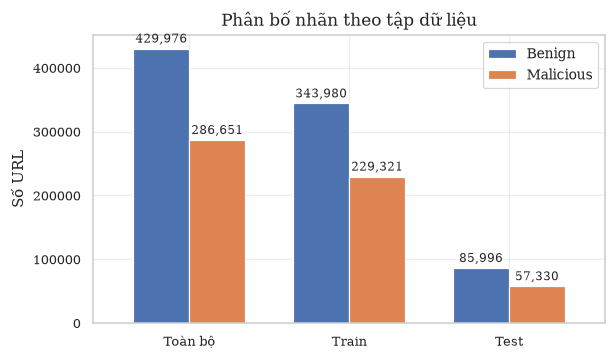

In [11]:
split_counts = pd.DataFrame(
    {
        "Toàn bộ": np.bincount(y, minlength=2),
        "Train": np.bincount(y_train, minlength=2),
        "Test": np.bincount(y_test, minlength=2),
    },
    index=CLASS_NAMES,
)
fig, ax = plt.subplots(figsize=(6, 3.4))
split_counts.T.plot(kind="bar", ax=ax, color=[COLORS["Benign"], COLORS["Malicious"]], width=0.7, rot=0)
for container in ax.containers:
    ax.bar_label(container, labels=[f"{int(v):,}" for v in container.datavalues], fontsize=8, padding=2)
ax.set_ylabel("Số URL")
ax.set_title("Phân bố nhãn theo tập dữ liệu")
ax.legend(title=None)
save_fig(fig, "fig1_class_distribution")
plt.show()

## 5. Chỉ số tổng hợp + khoảng tin cậy 95%

Khoảng tin cậy được ước lượng bằng **bootstrap phân vị** (lấy mẫu lại tập kiểm tra có hoàn lại `N_BOOTSTRAP` lần). Trước đó, hàm tính nhanh được đối chiếu với các hàm chuẩn của scikit-learn.

In [12]:
point = metrics_from_arrays(y_test, y_pred, y_score)

reference = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Balanced Accuracy": balanced_accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred),
    "Recall (TPR)": recall_score(y_test, y_pred),
    "F1-score": f1_score(y_test, y_pred),
    "MCC": matthews_corrcoef(y_test, y_pred),
    "Cohen's Kappa": cohen_kappa_score(y_test, y_pred),
    "Log Loss": log_loss(y_test, y_score),
    "Brier Score": brier_score_loss(y_test, y_score),
}
for name, ref in reference.items():
    assert abs(point[name] - ref) < 1e-9, f"{name}: {point[name]} != {ref}"
print("Đã đối chiếu với scikit-learn: OK")

t0 = time.perf_counter()
boot = bootstrap_metrics(y_test, y_pred, y_score, N_BOOTSTRAP, RANDOM_STATE)
print(f"Bootstrap {N_BOOTSTRAP} lần trong {time.perf_counter() - t0:.1f}s")

metrics_table = pd.DataFrame(
    {
        "Metric": list(point.keys()),
        "Value": list(point.values()),
        "95% CI lower": [boot[m].quantile(0.025) for m in point],
        "95% CI upper": [boot[m].quantile(0.975) for m in point],
        "Better": ["↓" if m in LOWER_IS_BETTER else "↑" for m in point],
    }
)
TABLES["table3_metrics_ci"] = metrics_table
display(Markdown(f"**Bảng 3.** Hiệu năng LightGBM trên tập kiểm tra (n = {len(y_test):,}, ngưỡng = {DECISION_THRESHOLD})"))
display(metrics_table.round(4))

Đã đối chiếu với scikit-learn: OK
Bootstrap 1000 lần trong 91.1s


**Bảng 3.** Hiệu năng LightGBM trên tập kiểm tra (n = 143,326, ngưỡng = 0.5)

,Metric,Value,95% CI lower,95% CI upper,Better
0,Accuracy,0.9335,0.9323,0.9348,↑
1,Balanced Accuracy,0.9299,0.9286,0.9312,↑
2,Precision,0.9213,0.9191,0.9235,↑
3,Recall (TPR),0.9117,0.9095,0.9141,↑
4,Specificity (TNR),0.9481,0.9466,0.9495,↑
5,F1-score,0.9165,0.9148,0.9181,↑
6,MCC,0.8613,0.8587,0.8640,↑
7,Cohen's Kappa,0.8613,0.8586,0.8640,↑
8,ROC-AUC,0.9810,0.9805,0.9816,↑
9,PR-AUC (AP),0.9767,0.9760,0.9774,↑


In [15]:
report = pd.DataFrame(
    classification_report(y_test, y_pred, target_names=CLASS_NAMES, digits=4, output_dict=True)
).T
report["support"] = report["support"].astype(int)
TABLES["table4_per_class"] = report.reset_index(names="Class")
display(Markdown("**Bảng 4.** Precision / Recall / F1 theo từng lớp"))
display(report.round(4))

**Bảng 4.** Precision / Recall / F1 theo từng lớp

,precision,recall,f1-score,support
Benign,0.9415,0.9481,0.9448,85996
Malicious,0.9213,0.9117,0.9165,57330
accuracy,0.9335,0.9335,0.9335,0
macro avg,0.9314,0.9299,0.9306,143326
weighted avg,0.9335,0.9335,0.9335,143326


## 6. Ma trận nhầm lẫn

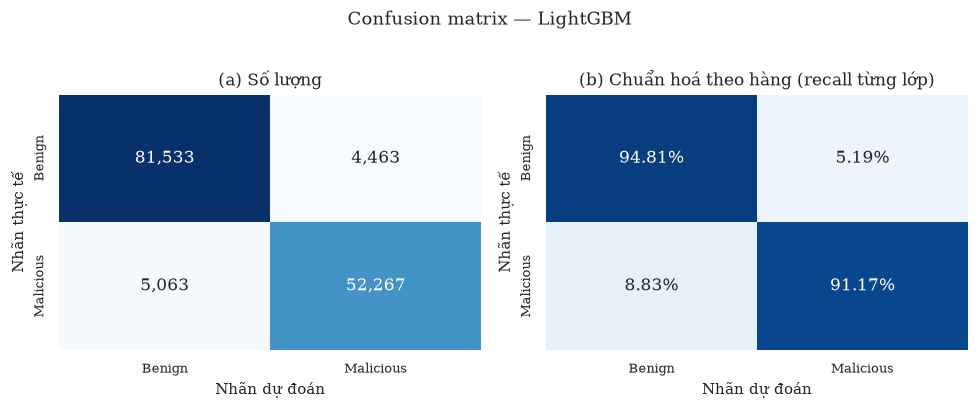

In [16]:
cm_norm = cm / cm.sum(axis=1, keepdims=True)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6))
sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 11})
axes[0].set_title("(a) Số lượng")
sns.heatmap(cm_norm, annot=True, fmt=".2%", cmap="Blues", cbar=False, ax=axes[1], vmin=0, vmax=1,
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, annot_kws={"size": 11})
axes[1].set_title("(b) Chuẩn hoá theo hàng (recall từng lớp)")
for ax in axes:
    ax.set_xlabel("Nhãn dự đoán")
    ax.set_ylabel("Nhãn thực tế")
fig.suptitle("Confusion matrix — LightGBM", y=1.02)
fig.tight_layout()
save_fig(fig, "fig2_confusion_matrix")
plt.show()

## 7. Đường cong ROC và Precision–Recall

Ngoài AUC, bài toán phát hiện phishing thường báo cáo **TPR tại FPR cố định** (0.1%, 1%, 5%), vì trong thực tế tỉ lệ cảnh báo nhầm phải rất thấp. Trục FPR dạng log (hình b) giúp nhìn rõ vùng này.

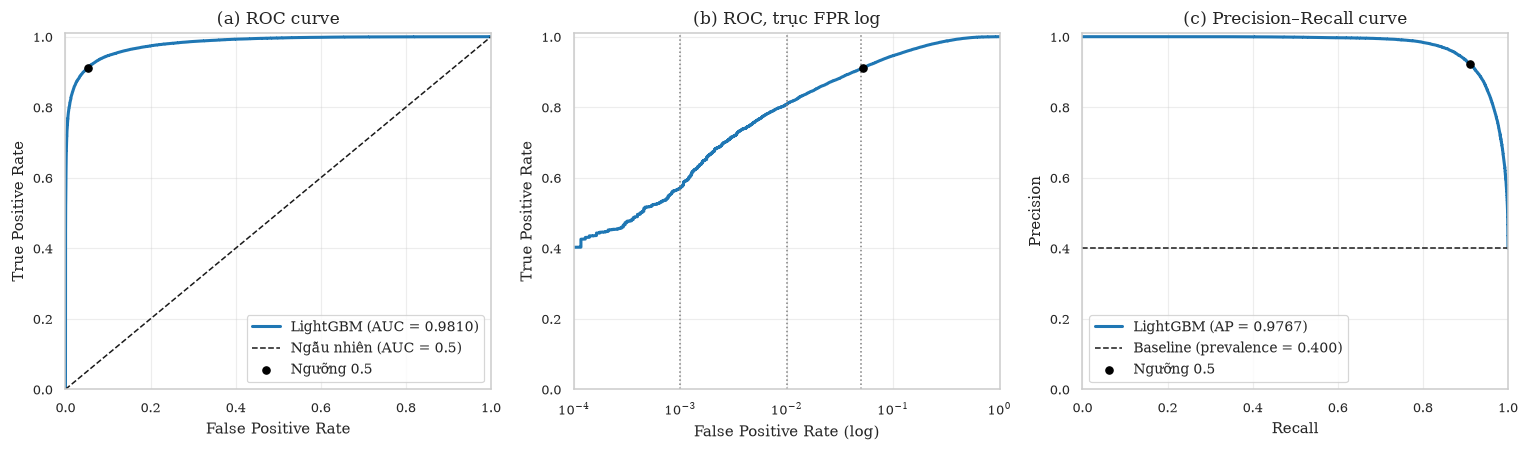

**Bảng 5.** TPR tại các mức FPR cố định

,FPR mục tiêu,TPR đạt được,Ngưỡng tương ứng
0,0.1%,0.5705,0.9886
1,1.0%,0.8089,0.8453
2,5.0%,0.9095,0.5113
3,10.0%,0.9462,0.3232


In [12]:
fpr, tpr, roc_thr = roc_curve(y_test, y_score)
prec_curve, rec_curve, _ = precision_recall_curve(y_test, y_score)
op_fpr, op_tpr = point["FPR"], point["Recall (TPR)"]
prevalence = y_test.mean()

fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
ax = axes[0]
ax.plot(fpr, tpr, color=COLORS["LightGBM"], lw=2, label=f"LightGBM (AUC = {point['ROC-AUC']:.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Ngẫu nhiên (AUC = 0.5)")
ax.scatter([op_fpr], [op_tpr], color="black", zorder=5, label=f"Ngưỡng {DECISION_THRESHOLD}")
ax.set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="(a) ROC curve", xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc="lower right")

ax = axes[1]
ax.semilogx(np.clip(fpr, 1e-5, 1), tpr, color=COLORS["LightGBM"], lw=2)
ax.scatter([op_fpr], [op_tpr], color="black", zorder=5)
for level in (1e-3, 1e-2, 5e-2):
    ax.axvline(level, color="grey", ls=":", lw=1)
ax.set(xlabel="False Positive Rate (log)", ylabel="True Positive Rate", title="(b) ROC, trục FPR log", xlim=(1e-4, 1), ylim=(0, 1.01))

ax = axes[2]
ax.plot(rec_curve, prec_curve, color=COLORS["LightGBM"], lw=2, label=f"LightGBM (AP = {point['PR-AUC (AP)']:.4f})")
ax.axhline(prevalence, color="k", ls="--", lw=1, label=f"Baseline (prevalence = {prevalence:.3f})")
ax.scatter([point["Recall (TPR)"]], [point["Precision"]], color="black", zorder=5, label=f"Ngưỡng {DECISION_THRESHOLD}")
ax.set(xlabel="Recall", ylabel="Precision", title="(c) Precision–Recall curve", xlim=(0, 1), ylim=(0, 1.01))
ax.legend(loc="lower left")
fig.tight_layout()
save_fig(fig, "fig3_roc_pr")
plt.show()

tpr_at_fpr = pd.DataFrame(
    [
        {
            "FPR mục tiêu": f"{level:.1%}",
            "TPR đạt được": float(np.interp(level, fpr, tpr)),
            "Ngưỡng tương ứng": float(roc_thr[max(np.searchsorted(fpr, level, side="right") - 1, 0)]),
        }
        for level in (0.001, 0.01, 0.05, 0.10)
    ]
)
TABLES["table5_tpr_at_fpr"] = tpr_at_fpr
display(Markdown("**Bảng 5.** TPR tại các mức FPR cố định"))
display(tpr_at_fpr.round(4))

## 8. Phân tích ngưỡng quyết định

Ngưỡng 0.5 chưa chắc tối ưu. Phần này quét ngưỡng từ 0.01 đến 0.99, rồi chỉ ra ngưỡng **tối đa F1** và ngưỡng **Youden's J** (tối đa TPR − FPR). Hai ngưỡng mà webapp dùng (`SUSPICIOUS_THRESHOLD`, `MALICIOUS_THRESHOLD` trong `config.py`) cũng được đánh dấu. Lưu ý: webapp áp các ngưỡng này lên xác suất **sau khi** cộng trừ điểm từ các luật, còn ở đây là xác suất gốc của mô hình.

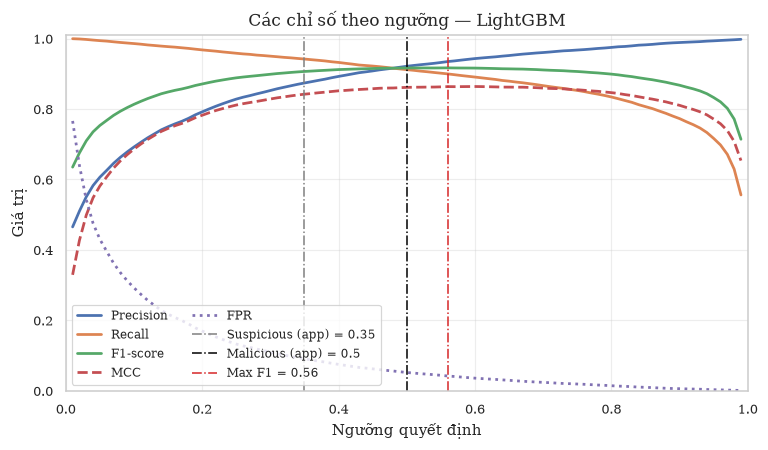

**Bảng 6.** Hiệu năng tại một số ngưỡng

,Threshold,Precision,Recall,F1-score,MCC,FPR,Accuracy,Ghi chú
0,0.2000,0.7919,0.9677,0.8710,0.7822,0.1696,0.8854,
1,0.3000,0.8525,0.9500,0.8986,0.8283,0.1096,0.9142,
2,0.3500,0.8739,0.9418,0.9066,0.8420,0.0906,0.9224,app suspicious
3,0.4000,0.8925,0.9322,0.9119,0.8516,0.0748,0.9280,
4,0.4646,0.9125,0.9192,0.9158,0.8594,0.0587,0.9324,Youden's J
5,0.5000,0.9213,0.9117,0.9165,0.8613,0.0519,0.9335,app malicious / mặc định
6,0.5600,0.9347,0.8996,0.9168,0.8635,0.0419,0.9347,max F1
7,0.6000,0.9431,0.8907,0.9161,0.8638,0.0358,0.9348,
8,0.7000,0.9603,0.8662,0.9108,0.8593,0.0239,0.9322,
9,0.8000,0.9748,0.8341,0.8990,0.8464,0.0143,0.9250,


In [13]:
def sweep_thresholds(y_true, scores, thresholds):
    rows = []
    for t in thresholds:
        pred = (scores >= t).astype(int)
        tn, fp, fn, tp = np.bincount(y_true * 2 + pred, minlength=4).astype(float)
        precision = tp / (tp + fp) if tp + fp else 1.0
        recall = tp / (tp + fn) if tp + fn else 0.0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
        den = np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn))
        rows.append(
            {
                "Threshold": t,
                "Precision": precision,
                "Recall": recall,
                "F1-score": f1,
                "MCC": (tp * tn - fp * fn) / den if den else 0.0,
                "FPR": fp / (fp + tn) if fp + tn else 0.0,
                "Accuracy": (tp + tn) / (tp + tn + fp + fn),
            }
        )
    return pd.DataFrame(rows)


grid = np.round(np.linspace(0.01, 0.99, 99), 2)
sweep = sweep_thresholds(y_test, y_score, grid)
best_f1_thr = float(sweep.loc[sweep["F1-score"].idxmax(), "Threshold"])
youden_thr = float(roc_thr[np.argmax(tpr - fpr)])

fig, ax = plt.subplots(figsize=(8, 4.2))
for col, style in [("Precision", "-"), ("Recall", "-"), ("F1-score", "-"), ("MCC", "--"), ("FPR", ":")]:
    ax.plot(sweep["Threshold"], sweep[col], style, lw=1.8, label=col)
marks = [
    (SUSPICIOUS_THRESHOLD, "grey", f"Suspicious (app) = {SUSPICIOUS_THRESHOLD}"),
    (MALICIOUS_THRESHOLD, "black", f"Malicious (app) = {MALICIOUS_THRESHOLD}"),
    (best_f1_thr, "tab:red", f"Max F1 = {best_f1_thr:.2f}"),
]
for value, color, label in marks:
    ax.axvline(value, color=color, ls="-.", lw=1, label=label)
ax.set(xlabel="Ngưỡng quyết định", ylabel="Giá trị", title="Các chỉ số theo ngưỡng — LightGBM", xlim=(0, 1), ylim=(0, 1.01))
ax.legend(ncol=2, fontsize=8, loc="lower left")
save_fig(fig, "fig4_threshold_analysis")
plt.show()

selected = sorted({0.2, 0.3, SUSPICIOUS_THRESHOLD, 0.4, MALICIOUS_THRESHOLD, 0.6, 0.7, 0.8, round(best_f1_thr, 2), round(youden_thr, 4)})
threshold_table = sweep_thresholds(y_test, y_score, selected)
notes = {SUSPICIOUS_THRESHOLD: "app suspicious", MALICIOUS_THRESHOLD: "app malicious / mặc định",
         round(best_f1_thr, 2): "max F1", round(youden_thr, 4): "Youden's J"}
threshold_table["Ghi chú"] = threshold_table["Threshold"].map(lambda t: notes.get(t, ""))
TABLES["table6_thresholds"] = threshold_table
display(Markdown("**Bảng 6.** Hiệu năng tại một số ngưỡng"))
display(threshold_table.round(4))

## 9. Hiệu chuẩn xác suất (calibration)

Webapp cộng trừ trực tiếp vào xác suất của mô hình, nên cần biết xác suất này có **phản ánh đúng tần suất thực tế** hay không. Biểu đồ reliability càng sát đường chéo thì mô hình càng được hiệu chuẩn tốt. **ECE** (Expected Calibration Error) là trung bình có trọng số của độ lệch giữa xác suất dự đoán và tần suất thực ở từng bin; **MCE** là độ lệch lớn nhất. Lưu ý: mô hình được huấn luyện với `class_weight="balanced"`, điều này có thể làm xác suất bị lệch so với tỉ lệ lớp thực tế.

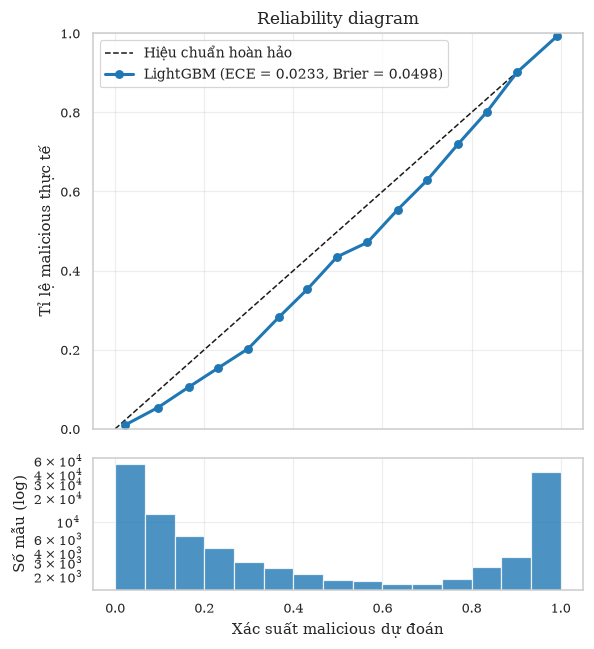

ECE = 0.0233 | MCE = 0.0959 | Brier = 0.0498


In [14]:
N_BINS = 15
frac_pos, mean_pred = calibration_curve(y_test, y_score, n_bins=N_BINS, strategy="uniform")
bin_ids = np.minimum((y_score * N_BINS).astype(int), N_BINS - 1)
bin_counts = np.bincount(bin_ids, minlength=N_BINS)
bin_conf = np.bincount(bin_ids, weights=y_score, minlength=N_BINS)
bin_true = np.bincount(bin_ids, weights=y_test, minlength=N_BINS)
nonempty = bin_counts > 0
gaps = np.abs(bin_conf[nonempty] / bin_counts[nonempty] - bin_true[nonempty] / bin_counts[nonempty])
ece = float(np.sum(gaps * bin_counts[nonempty]) / len(y_score))
mce = float(gaps.max())

fig, axes = plt.subplots(2, 1, figsize=(5.5, 6), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
axes[0].plot([0, 1], [0, 1], "k--", lw=1, label="Hiệu chuẩn hoàn hảo")
axes[0].plot(mean_pred, frac_pos, "o-", color=COLORS["LightGBM"], lw=2,
             label=f"LightGBM (ECE = {ece:.4f}, Brier = {point['Brier Score']:.4f})")
axes[0].set(ylabel="Tỉ lệ malicious thực tế", title="Reliability diagram", ylim=(0, 1))
axes[0].legend(loc="upper left")
axes[1].hist(y_score, bins=N_BINS, range=(0, 1), color=COLORS["LightGBM"], alpha=0.8)
axes[1].set_yscale("log")
axes[1].set(xlabel="Xác suất malicious dự đoán", ylabel="Số mẫu (log)")
fig.tight_layout()
save_fig(fig, "fig5_calibration")
plt.show()
print(f"ECE = {ece:.4f} | MCE = {mce:.4f} | Brier = {point['Brier Score']:.4f}")

## 10. Phân phối điểm và thống kê KS

Thống kê **Kolmogorov–Smirnov (KS)** đo khoảng cách lớn nhất giữa hai hàm phân phối tích luỹ của điểm số lớp benign và lớp malicious. KS càng lớn thì mô hình tách hai lớp càng tốt.

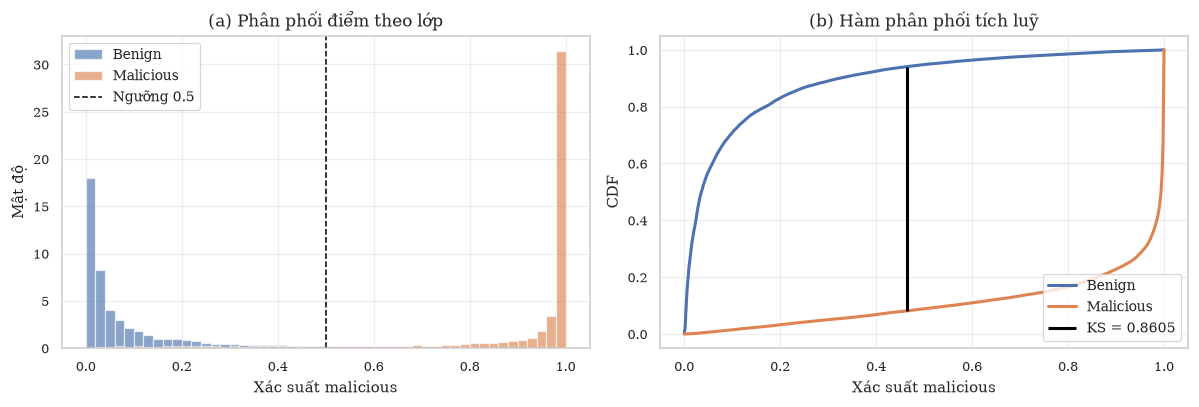

KS statistic = 0.8605 (p-value = 0)


In [15]:
scores_benign, scores_mal = y_score[y_test == 0], y_score[y_test == 1]
ks = stats.ks_2samp(scores_mal, scores_benign)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.linspace(0, 1, 51)
axes[0].hist(scores_benign, bins=bins, alpha=0.65, color=COLORS["Benign"], label="Benign", density=True)
axes[0].hist(scores_mal, bins=bins, alpha=0.65, color=COLORS["Malicious"], label="Malicious", density=True)
axes[0].axvline(DECISION_THRESHOLD, color="black", ls="--", lw=1, label=f"Ngưỡng {DECISION_THRESHOLD}")
axes[0].set(xlabel="Xác suất malicious", ylabel="Mật độ", title="(a) Phân phối điểm theo lớp")
axes[0].legend()

xs = np.linspace(0, 1, 501)
cdf_b = np.searchsorted(np.sort(scores_benign), xs, side="right") / len(scores_benign)
cdf_m = np.searchsorted(np.sort(scores_mal), xs, side="right") / len(scores_mal)
k = int(np.argmax(np.abs(cdf_b - cdf_m)))
axes[1].plot(xs, cdf_b, color=COLORS["Benign"], lw=2, label="Benign")
axes[1].plot(xs, cdf_m, color=COLORS["Malicious"], lw=2, label="Malicious")
axes[1].vlines(xs[k], cdf_m[k], cdf_b[k], color="black", lw=2, label=f"KS = {ks.statistic:.4f}")
axes[1].set(xlabel="Xác suất malicious", ylabel="CDF", title="(b) Hàm phân phối tích luỹ")
axes[1].legend(loc="lower right")
fig.tight_layout()
save_fig(fig, "fig6_score_distribution")
plt.show()
print(f"KS statistic = {ks.statistic:.4f} (p-value = {ks.pvalue:.3g})")

## 11. Độ quan trọng đặc trưng và SHAP

- **Gain**: tổng mức giảm loss mà một đặc trưng đóng góp qua tất cả các lần split → phản ánh mức ảnh hưởng.
- **Split**: số lần đặc trưng được dùng để split → phản ánh tần suất sử dụng.
- **SHAP** (TreeExplainer): mức đóng góp của từng đặc trưng vào từng dự đoán cụ thể. Mỗi điểm trên biểu đồ beeswarm là một URL, màu thể hiện giá trị đặc trưng cao hay thấp.

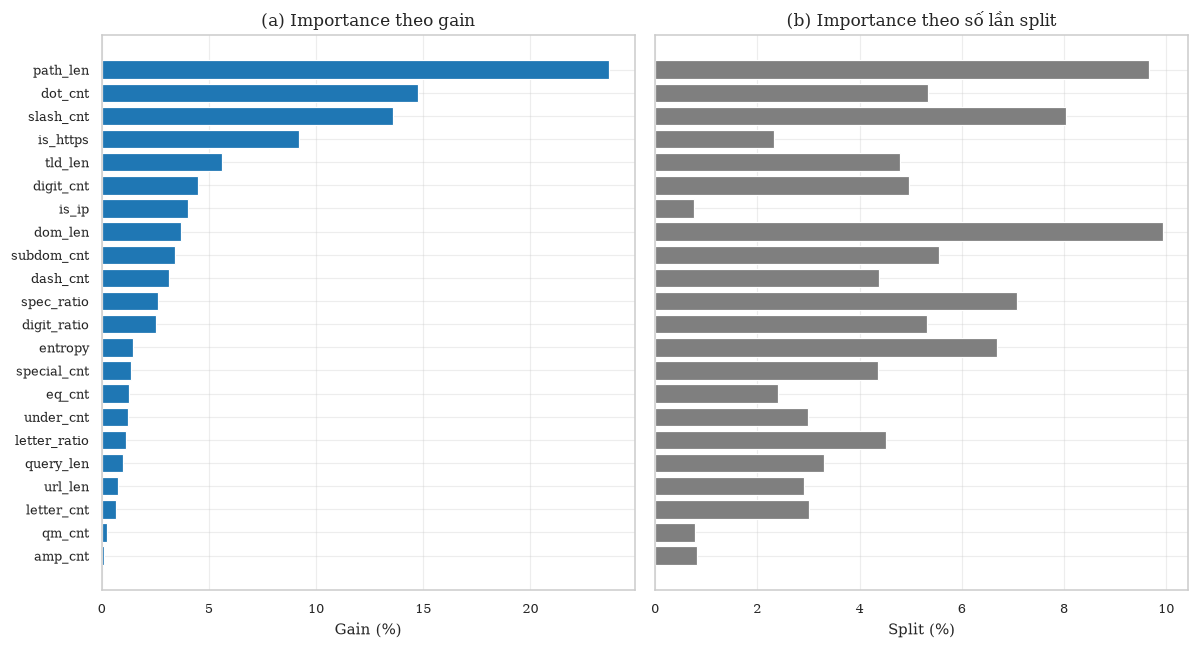

**Bảng 7.** Độ quan trọng đặc trưng của LightGBM

,Rank,Feature,Gain,Split,Gain (%),Split (%)
0,1,path_len,1467364.333,1796,23.673,9.656
1,2,dot_cnt,914078.190,993,14.747,5.339
2,3,slash_cnt,842565.754,1496,13.593,8.043
3,4,is_https,569618.822,434,9.190,2.333
4,5,tld_len,348125.837,893,5.616,4.801
5,6,digit_cnt,277206.942,923,4.472,4.962
6,7,is_ip,248582.064,142,4.010,0.763
7,8,dom_len,229399.308,1847,3.701,9.930
8,9,subdom_cnt,210559.089,1034,3.397,5.559
9,10,dash_cnt,194244.734,815,3.134,4.382


In [16]:
booster = lgb_model.booster_
importance = pd.DataFrame(
    {
        "Feature": booster.feature_name(),
        "Gain": booster.feature_importance(importance_type="gain"),
        "Split": booster.feature_importance(importance_type="split"),
    }
)
importance["Gain (%)"] = importance["Gain"] / importance["Gain"].sum() * 100
importance["Split (%)"] = importance["Split"] / importance["Split"].sum() * 100
importance = importance.sort_values("Gain (%)", ascending=False).reset_index(drop=True)
importance.insert(0, "Rank", np.arange(1, len(importance) + 1))
TABLES["table7_feature_importance"] = importance

fig, axes = plt.subplots(1, 2, figsize=(11, 6), sharey=True)
order = importance.iloc[::-1]
axes[0].barh(order["Feature"], order["Gain (%)"], color=COLORS["LightGBM"])
axes[0].set(xlabel="Gain (%)", title="(a) Importance theo gain")
axes[1].barh(order["Feature"], order["Split (%)"], color="#7f7f7f")
axes[1].set(xlabel="Split (%)", title="(b) Importance theo số lần split")
fig.tight_layout()
save_fig(fig, "fig7_feature_importance")
plt.show()
display(Markdown("**Bảng 7.** Độ quan trọng đặc trưng của LightGBM"))
display(importance.round(3))

D:\GITproject\Hybrid-Guard\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


SHAP cho 5,000 URL trong 9.9s


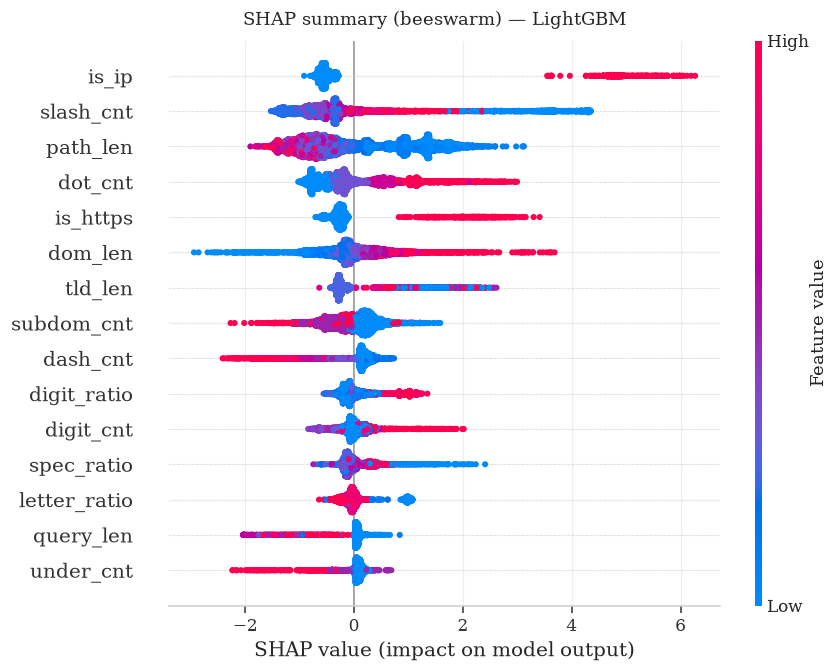

**Bảng 8.** Trung bình |SHAP| (log-odds) theo đặc trưng

,Feature,mean |SHAP|
0,is_ip,0.9949
1,slash_cnt,0.8942
2,path_len,0.8823
3,dot_cnt,0.5979
4,is_https,0.4913
5,dom_len,0.4649
6,tld_len,0.4460
7,subdom_cnt,0.3381
8,dash_cnt,0.3270
9,digit_ratio,0.2289


In [17]:
shap_importance = None
if RUN_SHAP:
    try:
        import shap
    except ImportError:
        shap = None
        print("Chưa cài shap — bỏ qua. Cài bằng: pip install shap")
    if shap is not None:
        X_shap = X_test.sample(n=min(SHAP_SAMPLE_SIZE, len(X_test)), random_state=RANDOM_STATE)
        t0 = time.perf_counter()
        shap_values = shap.TreeExplainer(lgb_model).shap_values(X_shap)
        if isinstance(shap_values, list):
            shap_values = shap_values[1]
        shap_values = np.asarray(shap_values)
        if shap_values.ndim == 3:
            shap_values = shap_values[:, :, 1]
        print(f"SHAP cho {len(X_shap):,} URL trong {time.perf_counter() - t0:.1f}s")

        shap.summary_plot(shap_values, X_shap, max_display=15, show=False, plot_size=(8, 6))
        fig = plt.gcf()
        fig.suptitle("SHAP summary (beeswarm) — LightGBM", y=1.01)
        save_fig(fig, "fig8_shap_beeswarm")
        plt.show()

        shap_importance = (
            pd.Series(np.abs(shap_values).mean(axis=0), index=X_shap.columns, name="mean |SHAP|")
            .sort_values(ascending=False)
            .rename_axis("Feature")
            .reset_index()
        )
        TABLES["table8_shap_importance"] = shap_importance
        display(Markdown("**Bảng 8.** Trung bình |SHAP| (log-odds) theo đặc trưng"))
        display(shap_importance.round(4))

## 12. Kiểm định chéo phân tầng k-fold

Huấn luyện lại LightGBM với **đúng siêu tham số của artifact** trên `CV_FOLDS` fold phân tầng của toàn bộ dữ liệu, rồi báo cáo **mean ± std**. Độ lệch chuẩn nhỏ cho thấy kết quả ổn định, không phụ thuộc vào một lần chia train/test cụ thể.

Fold 1: F1 = 0.9175 | AUC = 0.9808 | 32.0s


Fold 2: F1 = 0.9168 | AUC = 0.9810 | 36.5s


Fold 3: F1 = 0.9175 | AUC = 0.9813 | 35.2s


Fold 4: F1 = 0.9183 | AUC = 0.9817 | 63.3s


Fold 5: F1 = 0.9168 | AUC = 0.9809 | 42.3s


**Bảng 9.** Kết quả 5-fold stratified cross-validation

,Accuracy,Balanced Accuracy,Precision,Recall (TPR),Specificity (TNR),F1-score,MCC,Cohen's Kappa,ROC-AUC,PR-AUC (AP),Log Loss,Brier Score,FPR,FNR,Train time (s)
Fold,,,,,,,,,,,,,,,
1,0.9344,0.9307,0.9226,0.9125,0.9490,0.9175,0.8630,0.8630,0.9808,0.9767,0.1702,0.0495,0.0510,0.0875,32.0267
2,0.9339,0.9300,0.9233,0.9105,0.9496,0.9168,0.8621,0.8620,0.9810,0.9767,0.1700,0.0496,0.0504,0.0895,36.4525
3,0.9344,0.9305,0.9242,0.9109,0.9502,0.9175,0.8632,0.8631,0.9813,0.9772,0.1684,0.0490,0.0498,0.0891,35.1953
4,0.9351,0.9313,0.9241,0.9126,0.9500,0.9183,0.8645,0.8644,0.9817,0.9776,0.1673,0.0487,0.0500,0.0874,63.2634
5,0.9341,0.9298,0.9255,0.9083,0.9513,0.9168,0.8623,0.8622,0.9809,0.9767,0.1695,0.0493,0.0487,0.0917,42.2983


,Mean ± Std
Accuracy,0.9344 ± 0.0004
Balanced Accuracy,0.9305 ± 0.0006
Precision,0.9239 ± 0.0011
Recall (TPR),0.9110 ± 0.0017
Specificity (TNR),0.9500 ± 0.0008
F1-score,0.9174 ± 0.0006
MCC,0.8630 ± 0.0009
Cohen's Kappa,0.8630 ± 0.0009
ROC-AUC,0.9811 ± 0.0004
PR-AUC (AP),0.9770 ± 0.0004


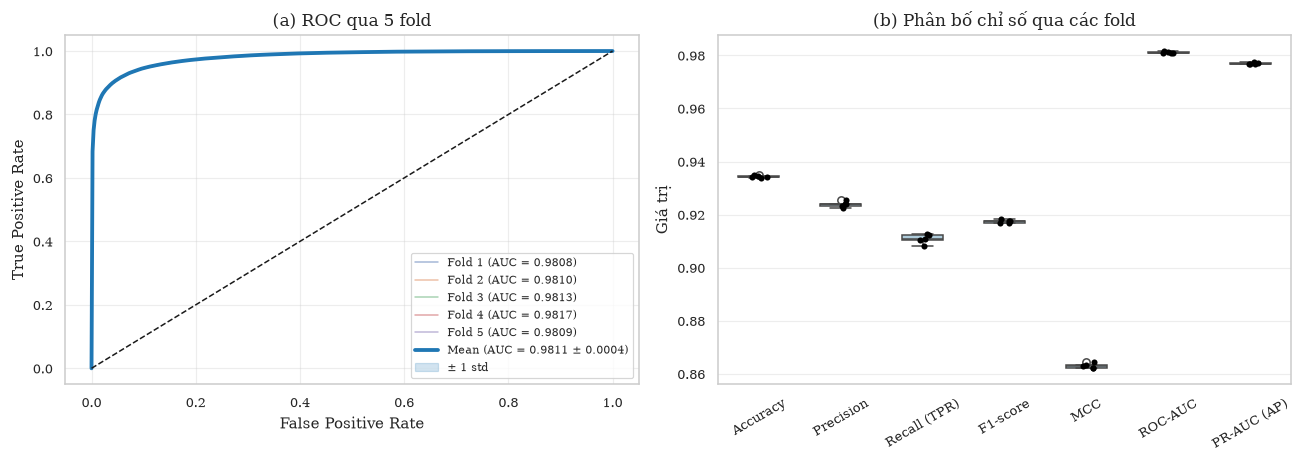

In [18]:
cv_table = None
if RUN_CV:
    skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)
    lgb_params = lgb_model.get_params()
    mean_fpr = np.linspace(0, 1, 501)
    cv_rows, cv_tprs = [], []
    for fold, (tr, va) in enumerate(skf.split(X, y), start=1):
        model_cv = LGBMClassifier(**lgb_params)
        t0 = time.perf_counter()
        model_cv.fit(X.iloc[tr], y[tr])
        fit_time = time.perf_counter() - t0
        s = model_cv.predict_proba(X.iloc[va])[:, 1]
        row = metrics_from_arrays(y[va], (s >= DECISION_THRESHOLD).astype(int), s)
        row["Fold"] = fold
        row["Train time (s)"] = fit_time
        cv_rows.append(row)
        f_fpr, f_tpr, _ = roc_curve(y[va], s)
        interp = np.interp(mean_fpr, f_fpr, f_tpr)
        interp[0] = 0.0
        cv_tprs.append(interp)
        print(f"Fold {fold}: F1 = {row['F1-score']:.4f} | AUC = {row['ROC-AUC']:.4f} | {fit_time:.1f}s")

    cv_df = pd.DataFrame(cv_rows).set_index("Fold")
    cv_table = pd.DataFrame({"Mean ± Std": {c: mean_std(cv_df[c]) for c in cv_df.columns}})
    TABLES["table9_cv_folds"] = cv_df.reset_index()
    TABLES["table9_cv_summary"] = cv_table.reset_index(names="Metric")
    display(Markdown(f"**Bảng 9.** Kết quả {CV_FOLDS}-fold stratified cross-validation"))
    display(cv_df.round(4))
    display(cv_table)

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
    for i, t in enumerate(cv_tprs, start=1):
        axes[0].plot(mean_fpr, t, lw=1, alpha=0.5, label=f"Fold {i} (AUC = {cv_df.loc[i, 'ROC-AUC']:.4f})")
    mean_tpr, std_tpr = np.mean(cv_tprs, axis=0), np.std(cv_tprs, axis=0)
    axes[0].plot(mean_fpr, mean_tpr, color=COLORS["LightGBM"], lw=2.5,
                 label=f"Mean (AUC = {mean_std(cv_df['ROC-AUC'])})")
    axes[0].fill_between(mean_fpr, np.clip(mean_tpr - std_tpr, 0, 1), np.clip(mean_tpr + std_tpr, 0, 1),
                         color=COLORS["LightGBM"], alpha=0.2, label="± 1 std")
    axes[0].plot([0, 1], [0, 1], "k--", lw=1)
    axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title=f"(a) ROC qua {CV_FOLDS} fold")
    axes[0].legend(loc="lower right", fontsize=7.5)

    box_cols = ["Accuracy", "Precision", "Recall (TPR)", "F1-score", "MCC", "ROC-AUC", "PR-AUC (AP)"]
    sns.boxplot(data=cv_df[box_cols], ax=axes[1], color="#a6cee3", width=0.5)
    sns.stripplot(data=cv_df[box_cols], ax=axes[1], color="black", size=4)
    axes[1].set(title="(b) Phân bố chỉ số qua các fold", ylabel="Giá trị")
    axes[1].tick_params(axis="x", rotation=30)
    fig.tight_layout()
    save_fig(fig, "fig9_cross_validation")
    plt.show()
else:
    print("RUN_CV = False — bỏ qua.")

## 13. Learning curve

Huấn luyện LightGBM trên các tỉ lệ khác nhau của tập train rồi đánh giá trên **cùng tập test**. Biểu đồ trả lời hai câu hỏi: thêm dữ liệu có còn cải thiện mô hình không, và khoảng cách train–test (mức overfitting) lớn đến đâu.

   1% (  5,733 mẫu): Test F1 = 0.8800


   2% ( 11,466 mẫu): Test F1 = 0.8943


   5% ( 28,665 mẫu): Test F1 = 0.9058


  10% ( 57,330 mẫu): Test F1 = 0.9103


  25% (143,325 mẫu): Test F1 = 0.9136


  50% (286,650 mẫu): Test F1 = 0.9152


 100% (573,301 mẫu): Test F1 = 0.9165


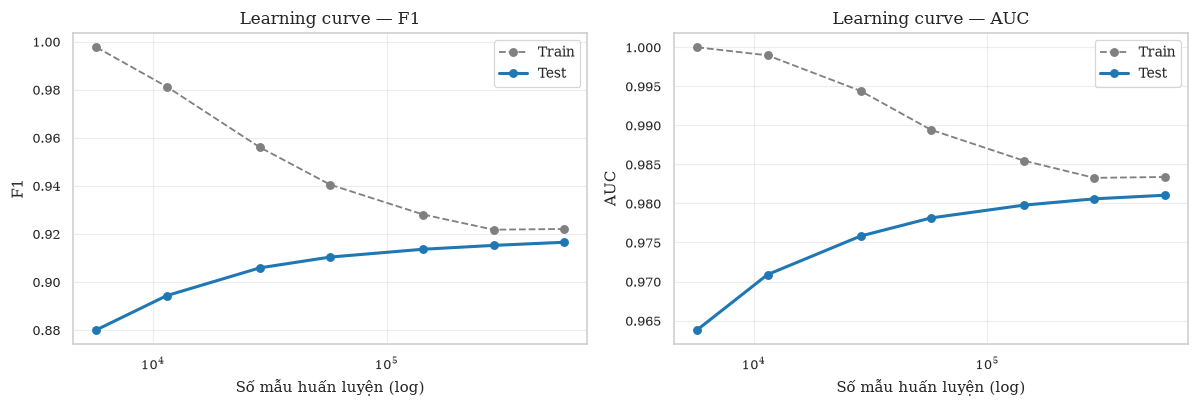

,Fraction,Train size,Train F1,Test F1,Train AUC,Test AUC
0,0.01,5733,0.9976,0.8800,1.0000,0.9638
1,0.02,11466,0.9812,0.8943,0.9989,0.9709
2,0.05,28665,0.9560,0.9058,0.9944,0.9758
3,0.10,57330,0.9405,0.9103,0.9894,0.9781
4,0.25,143325,0.9280,0.9136,0.9855,0.9798
5,0.50,286650,0.9217,0.9152,0.9833,0.9806
6,1.00,573301,0.9220,0.9165,0.9834,0.9810


In [19]:
lc_df = None
if RUN_LEARNING_CURVE:
    fractions = [0.01, 0.02, 0.05, 0.1, 0.25, 0.5, 1.0]
    lgb_params = lgb_model.get_params()
    rng = np.random.default_rng(RANDOM_STATE)
    lc_rows = []
    for frac in fractions:
        if frac < 1.0:
            sub, _ = train_test_split(np.arange(len(X_train)), train_size=frac, stratify=y_train, random_state=RANDOM_STATE)
        else:
            sub = np.arange(len(X_train))
        model_lc = LGBMClassifier(**lgb_params).fit(X_train.iloc[sub], y_train[sub])
        eval_sub = sub if len(sub) <= 50_000 else rng.choice(sub, 50_000, replace=False)
        s_tr = model_lc.predict_proba(X_train.iloc[eval_sub])[:, 1]
        s_te = model_lc.predict_proba(X_test)[:, 1]
        lc_rows.append(
            {
                "Fraction": frac,
                "Train size": len(sub),
                "Train F1": f1_score(y_train[eval_sub], s_tr >= DECISION_THRESHOLD),
                "Test F1": f1_score(y_test, s_te >= DECISION_THRESHOLD),
                "Train AUC": roc_auc_score(y_train[eval_sub], s_tr),
                "Test AUC": roc_auc_score(y_test, s_te),
            }
        )
        print(f"{frac:>5.0%} ({len(sub):>7,} mẫu): Test F1 = {lc_rows[-1]['Test F1']:.4f}")
    lc_df = pd.DataFrame(lc_rows)
    TABLES["table10_learning_curve"] = lc_df

    fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
    for ax, metric in zip(axes, ["F1", "AUC"]):
        ax.plot(lc_df["Train size"], lc_df[f"Train {metric}"], "o--", color="grey", label="Train")
        ax.plot(lc_df["Train size"], lc_df[f"Test {metric}"], "o-", color=COLORS["LightGBM"], lw=2, label="Test")
        ax.set_xscale("log")
        ax.set(xlabel="Số mẫu huấn luyện (log)", ylabel=metric, title=f"Learning curve — {metric}")
        ax.legend()
    fig.tight_layout()
    save_fig(fig, "fig10_learning_curve")
    plt.show()
    display(lc_df.round(4))
else:
    print("RUN_LEARNING_CURVE = False — bỏ qua.")

## 14. So sánh với Random Forest và Decision Tree

Ba mô hình được đánh giá trên **cùng tập test**. Ngoài bảng chỉ số, phần này dùng hai phép kiểm định cho dữ liệu ghép cặp:
- **McNemar** (có hiệu chỉnh liên tục): kiểm tra xem hai mô hình có tỉ lệ lỗi khác nhau thật sự không, dựa trên các mẫu mà chỉ một trong hai mô hình đoán sai.
- **Paired bootstrap**: khoảng tin cậy 95% cho hiệu số F1, MCC, AUC (LightGBM − baseline). Nếu khoảng không chứa 0 thì khác biệt có ý nghĩa thống kê.

In [17]:
models_eval = {
    "LightGBM": {
        "score": y_score,
        "latency_us": lgb_latency_us,
        "size_mb": LGB_MODEL_PATH.stat().st_size / 2**20,
    }
}
for name, path in BASELINE_MODEL_PATHS.items():
    if not path.exists():
        print(f"Không tìm thấy {name}: {path} — bỏ qua.")
        continue
    base_artifact = joblib.load(path)
    assert list(base_artifact["feature_names"]) == feature_names
    t0 = time.perf_counter()
    s = base_artifact["model"].predict_proba(X_test)[:, 1]
    models_eval[name] = {
        "score": s,
        "latency_us": (time.perf_counter() - t0) / len(X_test) * 1e6,
        "size_mb": path.stat().st_size / 2**20,
    }

compare_rows = []
for name, info in models_eval.items():
    info["pred"] = (info["score"] >= DECISION_THRESHOLD).astype(int)
    row = {"Model": name, **metrics_from_arrays(y_test, info["pred"], info["score"])}
    row["Latency (µs/URL)"] = info["latency_us"]
    row["Size (MB)"] = info["size_mb"]
    compare_rows.append(row)
compare_df = pd.DataFrame(compare_rows).set_index("Model")
TABLES["table11_model_comparison"] = compare_df.reset_index()

cols = ["Accuracy", "Precision", "Recall (TPR)", "F1-score", "MCC", "ROC-AUC", "PR-AUC (AP)", "FPR", "Latency (µs/URL)", "Size (MB)"]
display(Markdown("**Bảng 11.** So sánh mô hình trên cùng tập test (giá trị tốt nhất được tô đậm)"))
best = {c: (compare_df[c].idxmin() if c in LOWER_IS_BETTER | {"Latency (µs/URL)", "Size (MB)"} else compare_df[c].idxmax()) for c in cols}
display(compare_df[cols].style.format("{:.4f}").apply(
    lambda col: ["font-weight: bold" if idx == best[col.name] else "" for idx in col.index], axis=0
))

**Bảng 11.** So sánh mô hình trên cùng tập test (giá trị tốt nhất được tô đậm)

,Accuracy,Precision,Recall (TPR),F1-score,MCC,ROC-AUC,PR-AUC (AP),FPR,Latency (µs/URL),Size (MB)
Model,,,,,,,,,,
LightGBM,0.9335,0.9213,0.9117,0.9165,0.8613,0.9810,0.9767,0.0519,4.0585,2.0074
Random Forest,0.9414,0.9406,0.9112,0.9256,0.8777,0.9835,0.9793,0.0384,5.1429,326.4693
Decision Tree,0.9283,0.9226,0.8959,0.9090,0.8501,0.9492,0.9324,0.0501,0.3217,2.0565


In [ ]:
def mcnemar_test(y_true, pred_a, pred_b):
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    b = int(np.sum(a_ok & ~b_ok))  # A đúng, B sai
    c = int(np.sum(~a_ok & b_ok))  # A sai, B đúng
    chi2 = (abs(b - c) - 1) ** 2 / (b + c) if b + c else 0.0
    return b, c, chi2, float(stats.chi2.sf(chi2, df=1))


def paired_bootstrap_delta(y_true, info_a, info_b, n_boot, seed):
    rng = np.random.default_rng(seed)
    n = len(y_true)
    deltas = {"ΔF1": [], "ΔMCC": [], "ΔROC-AUC": []}
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        ma = metrics_from_arrays(y_true[idx], info_a["pred"][idx], info_a["score"][idx])
        mb = metrics_from_arrays(y_true[idx], info_b["pred"][idx], info_b["score"][idx])
        deltas["ΔF1"].append(ma["F1-score"] - mb["F1-score"])
        deltas["ΔMCC"].append(ma["MCC"] - mb["MCC"])
        deltas["ΔROC-AUC"].append(ma["ROC-AUC"] - mb["ROC-AUC"])
    return {k: np.array(v) for k, v in deltas.items()}


sig_rows = []
for name, info in models_eval.items():
    if name == "LightGBM":
        continue
    b, c, chi2, p_value = mcnemar_test(y_test, models_eval["LightGBM"]["pred"], info["pred"])
    deltas = paired_bootstrap_delta(y_test, models_eval["LightGBM"], info, N_BOOTSTRAP_COMPARE, RANDOM_STATE)
    row = {
        "So sánh": f"LightGBM vs {name}",
        "Chỉ LGB đúng (b)": b,
        "Chỉ baseline đúng (c)": c,
        "McNemar χ²": chi2,
        "p-value": "< 1e-16" if p_value < 1e-16 else f"{p_value:.3g}",
    }
    for key, values in deltas.items():
        row[f"{key} [95% CI]"] = f"{values.mean():+.4f} [{np.quantile(values, 0.025):+.4f}, {np.quantile(values, 0.975):+.4f}]"
    sig_rows.append(row)
significance_df = pd.DataFrame(sig_rows)
TABLES["table12_significance"] = significance_df
display(Markdown("**Bảng 12.** Kiểm định ý nghĩa thống kê (LightGBM so với baseline)"))
display(significance_df)

**Bảng 12.** Kiểm định ý nghĩa thống kê (LightGBM so với baseline)

,So sánh,Chỉ LGB đúng (b),Chỉ baseline đúng (c),McNemar χ²,p-value,ΔF1 [95% CI],ΔMCC [95% CI],ΔROC-AUC [95% CI]
0,LightGBM vs Random Forest,24711,4178,14592.510090,< 1e-16,"+0.1781 [+0.1755, +0.1810]","+0.2980 [+0.2939, +0.3026]","+0.1129 [+0.1111, +0.1145]"
1,LightGBM vs Decision Tree,28342,4063,18189.207962,< 1e-16,"+0.2010 [+0.1983, +0.2039]","+0.3459 [+0.3414, +0.3506]","+0.1233 [+0.1216, +0.1251]"


In [1]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.3))
for name, info in models_eval.items():
    m_fpr, m_tpr, _ = roc_curve(y_test, info["score"])
    m_prec, m_rec, _ = precision_recall_curve(y_test, info["score"])
    color = COLORS.get(name)
    axes[0].plot(m_fpr, m_tpr, lw=2, color=color, label=f"{name} (AUC = {compare_df.loc[name, 'ROC-AUC']:.4f})")
    axes[1].plot(m_rec, m_prec, lw=2, color=color, label=f"{name} (AP = {compare_df.loc[name, 'PR-AUC (AP)']:.4f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(xlabel="False Positive Rate", ylabel="True Positive Rate", title="(a) ROC curve")
axes[0].legend(loc="lower right")
axes[1].axhline(prevalence, color="k", ls="--", lw=1)
axes[1].set(xlabel="Recall", ylabel="Precision", title="(b) Precision–Recall curve", ylim=(0, 1.01))
axes[1].legend(loc="lower left")
fig.tight_layout()
save_fig(fig, "fig11_model_comparison_curves")
plt.show()

bar_metrics = ["Accuracy", "Precision", "Recall (TPR)", "F1-score", "MCC", "ROC-AUC"]
fig, ax = plt.subplots(figsize=(10, 3.8))
compare_df[bar_metrics].T.plot(kind="bar", ax=ax, rot=0, width=0.75,
                               color=[COLORS.get(m) for m in compare_df.index])
for container in ax.containers:
    ax.bar_label(container, fmt="%.3f", fontsize=7, padding=1, rotation=90)
ax.set(ylabel="Giá trị", title="So sánh chỉ số giữa các mô hình", ylim=(compare_df[bar_metrics].values.min() - 0.08, 1.04))
ax.legend(loc="lower right")
save_fig(fig, "fig12_model_comparison_bars")
plt.show()

NameError: name 'plt' is not defined

## 15. Phân tích lỗi

Liệt kê các URL mà mô hình **sai với độ tự tin cao nhất**:
- False positive: URL benign nhưng có điểm cao nhất.
- False negative: URL malicious nhưng có điểm thấp nhất.

Kèm theo là tỉ lệ lỗi theo các TLD phổ biến, giúp thấy mô hình yếu ở nhóm domain nào.

In [23]:
err = df_test.assign(y_true=y_test, score=y_score, y_pred=y_pred)
show_cols = [c for c in ["url", "dom", "tld", "url_len", "is_https", "entropy", "subdom_cnt", "score"] if c in err]

false_pos = err[(err.y_true == 0) & (err.y_pred == 1)].sort_values("score", ascending=False)
false_neg = err[(err.y_true == 1) & (err.y_pred == 0)].sort_values("score", ascending=True)
TABLES["table13_top_false_positives"] = false_pos[show_cols].head(50)
TABLES["table14_top_false_negatives"] = false_neg[show_cols].head(50)

with pd.option_context("display.max_colwidth", 80):
    display(Markdown(f"**False positive** ({len(false_pos):,} URL) — 15 URL điểm cao nhất"))
    display(false_pos[show_cols].head(15).round(4))
    display(Markdown(f"**False negative** ({len(false_neg):,} URL) — 15 URL điểm thấp nhất"))
    display(false_neg[show_cols].head(15).round(4))

**False positive** (4,463 URL) — 15 URL điểm cao nhất

,url,dom,tld,url_len,is_https,entropy,subdom_cnt,score
52253,141.2.66.26/en/,141.2.66.26,66.26,22,0,3.3908,2,0.9997
133772,198.164.154.3/~Heritage/RCN/SJ_Built_Frigates.htm,198.164.154.3,3,56,0,4.7112,2,0.9992
96293,http://OpenBeatBox.org,openbeatbox.org,org,22,0,3.7888,0,0.9978
126879,http://%7Bsburke%7D%20%7Bat%7D%20%7Bcpan.org%7D,%7bsburke%7d%20%7bat%7d%20%7bcpan.org%7d,org%7d,47,0,4.1551,0,0.9978
134701,http://slashdot.org,slashdot.org,org,19,0,3.5766,0,0.9977
56881,http://neudist.org,neudist.org,org,18,0,3.7947,0,0.9975
22137,'www.118bm.com/images/?us.battle.net/login/en/?rdf=hü4p\%3A\%2F^%2Fbmlú+(}w...,'www.118bm.com,com,143,0,5.9688,1,0.9972
61388,http://conservative.by,conservative.by,by,22,0,3.9706,0,0.9972
84855,https://www.civilservicejobs.service.gov.uk/job.cgi?1536981.0,www.civilservicejobs.service.gov.uk,gov.uk,61,1,4.5310,3,0.9969
18619,https://postcodefinder.guide/address/bb09aee06ca1fe769439135d44375095/,postcodefinder.guide,guide,70,1,4.5393,0,0.9969


**False negative** (5,063 URL) — 15 URL điểm thấp nhất

,url,dom,tld,url_len,is_https,entropy,subdom_cnt,score
35303,vk.com/skachat_minecraft_0_9_0_android,vk.com,com,45,0,4.2670,0,0.0012
48130,vk.com/vzlomannye_igry_dlya_android,vk.com,com,42,0,4.3141,0,0.0015
10852,http://lnkedn.com/2013/06/modi-kejriwal-sing-fun-number-ek-chatur-naar/,lnkedn.com,com,71,0,4.5942,0,0.0022
52475,www.chinahush.com/2014/12/27/can-common-views-of-chinese-women-be-changed,www.chinahush.com,com,80,0,4.4039,1,0.0025
68864,dianagarces.com/como-compartir-documentos-con-google-drive,dianagarces.com,com,65,0,4.1235,0,0.0030
114344,aboutusvisas.com/get-strong-support-letters-when-seeking-immigration-options/,aboutusvisas.com,com,84,0,4.1612,0,0.0031
123304,veganvet.net/west-los-angeles-veterinary-practice/,veganvet.net,net,57,0,4.0005,0,0.0033
67688,plqfg.tunadesign.top/yell/1747937/cousin-twice-journal-first-nanny-fright-as...,plqfg.tunadesign.top,top,89,0,4.6539,1,0.0036
96477,blog.theunical.com/google-api/google-docs-google-docs-viewer-now-supports-do...,blog.theunical.com,com,114,0,4.2774,1,0.0049
128669,worldmilitarynews.org/news_id/15339405/exercise-ramstein-dust-i-2015-is-unde...,worldmilitarynews.org,org,101,0,4.6191,0,0.0049


**Bảng 15.** Hiệu năng theo 15 TLD phổ biến nhất trong tập test

,TLD,Số URL,Tỉ lệ malicious,Accuracy,FPR,FNR
0,.com,81297,0.2276,0.9327,0.0364,0.1724
1,.org,11885,0.2003,0.9465,0.0316,0.1411
2,.net,4940,0.3468,0.8953,0.0471,0.2131
3,.cn,3169,0.9984,0.9912,0.8000,0.0076
4,.edu,2184,0.0023,0.9606,0.0381,0.6000
5,.ca,1774,0.0693,0.8106,0.1975,0.0813
6,.co.uk,1474,0.2327,0.9071,0.0787,0.1399
7,.top,1182,1.0000,0.9357,NaN,0.0643
8,.240,1107,1.0000,1.0000,NaN,0.0000
9,.info,954,0.6646,0.8553,0.3500,0.0410


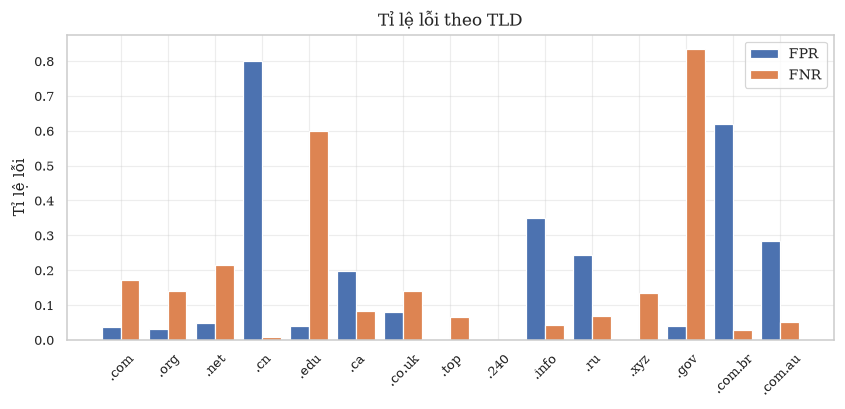

In [24]:
if "tld" in err:
    top_tlds = err["tld"].value_counts().head(15).index
    tld_rows = []
    for tld in top_tlds:
        part = err[err["tld"] == tld]
        neg, pos = part[part.y_true == 0], part[part.y_true == 1]
        tld_rows.append(
            {
                "TLD": f".{tld}",
                "Số URL": len(part),
                "Tỉ lệ malicious": pos.shape[0] / len(part),
                "Accuracy": float((part.y_true == part.y_pred).mean()),
                "FPR": float(neg.y_pred.mean()) if len(neg) else np.nan,
                "FNR": float(1 - pos.y_pred.mean()) if len(pos) else np.nan,
            }
        )
    tld_df = pd.DataFrame(tld_rows)
    TABLES["table15_error_by_tld"] = tld_df
    display(Markdown("**Bảng 15.** Hiệu năng theo 15 TLD phổ biến nhất trong tập test"))
    display(tld_df.round(4))

    fig, ax = plt.subplots(figsize=(9, 3.6))
    x = np.arange(len(tld_df))
    ax.bar(x - 0.2, tld_df["FPR"], width=0.4, color=COLORS["Benign"], label="FPR")
    ax.bar(x + 0.2, tld_df["FNR"], width=0.4, color=COLORS["Malicious"], label="FNR")
    ax.set_xticks(x, tld_df["TLD"], rotation=45)
    ax.set(ylabel="Tỉ lệ lỗi", title="Tỉ lệ lỗi theo TLD")
    ax.legend()
    save_fig(fig, "fig13_error_by_tld")
    plt.show()

## 16. Xuất kết quả và tóm tắt

In [25]:
for name, table in TABLES.items():
    table.to_csv(REPORT_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
    try:
        latex = table.to_latex(index=False, float_format="%.4f", escape=True)
        (REPORT_DIR / f"{name}.tex").write_text(latex, encoding="utf-8")
    except Exception as exc:  # to_latex cần jinja2
        print(f"Bỏ qua LaTeX cho {name}: {exc}")

summary = {
    "dataset": str(data_path),
    "n_total": int(n_total),
    "n_test": int(len(y_test)),
    "random_state": RANDOM_STATE,
    "decision_threshold": DECISION_THRESHOLD,
    "metrics": {k: float(v) for k, v in point.items()},
    "metrics_ci95": {m: [float(boot[m].quantile(0.025)), float(boot[m].quantile(0.975))] for m in point},
    "best_f1_threshold": best_f1_thr,
    "youden_threshold": youden_thr,
    "ece": ece,
    "ks_statistic": float(ks.statistic),
    "latency_us_per_url": lgb_latency_us,
}
if cv_table is not None:
    summary["cross_validation"] = cv_table["Mean ± Std"].to_dict()
(REPORT_DIR / "summary.json").write_text(json.dumps(summary, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Đã lưu {len(TABLES)} bảng và các hình vào: {REPORT_DIR}")
for path in sorted(REPORT_DIR.iterdir()):
    print("  -", path.name)

Đã lưu 17 bảng và các hình vào: D:\GITproject\Hybrid-Guard\artifacts\report\lgb_research
  - fig10_learning_curve.pdf
  - fig10_learning_curve.png
  - fig11_model_comparison_curves.pdf
  - fig11_model_comparison_curves.png
  - fig12_model_comparison_bars.pdf
  - fig12_model_comparison_bars.png
  - fig13_error_by_tld.pdf
  - fig13_error_by_tld.png
  - fig1_class_distribution.pdf
  - fig1_class_distribution.png
  - fig2_confusion_matrix.pdf
  - fig2_confusion_matrix.png
  - fig3_roc_pr.pdf
  - fig3_roc_pr.png
  - fig4_threshold_analysis.pdf
  - fig4_threshold_analysis.png
  - fig5_calibration.pdf
  - fig5_calibration.png
  - fig6_score_distribution.pdf
  - fig6_score_distribution.png
  - fig7_feature_importance.pdf
  - fig7_feature_importance.png
  - fig8_shap_beeswarm.pdf
  - fig8_shap_beeswarm.png
  - fig9_cross_validation.pdf
  - fig9_cross_validation.png
  - summary.json
  - table10_learning_curve.csv
  - table10_learning_curve.tex
  - table11_model_comparison.csv
  - table11_model_c

In [26]:
def ci(metric):
    row = metrics_table.set_index("Metric").loc[metric]
    return f"{row['Value']:.4f} (95% CI: {row['95% CI lower']:.4f}–{row['95% CI upper']:.4f})"


lines = [
    f"Trên tập kiểm tra gồm **{len(y_test):,} URL** (20% hold-out, phân tầng), mô hình LightGBM đạt "
    f"Accuracy {ci('Accuracy')}, F1-score {ci('F1-score')}, MCC {ci('MCC')} và ROC-AUC {ci('ROC-AUC')}.",
    f"Với ngưỡng {DECISION_THRESHOLD}, FPR = {point['FPR']:.2%} và FNR = {point['FNR']:.2%}; "
    f"tại FPR = 1%, mô hình phát hiện được {tpr_at_fpr.loc[1, 'TPR đạt được']:.2%} URL độc hại.",
    f"Ngưỡng tối đa F1 là {best_f1_thr:.2f} (F1 = {sweep['F1-score'].max():.4f}). "
    f"Mức hiệu chuẩn: ECE = {ece:.4f}, Brier = {point['Brier Score']:.4f}; thống kê KS = {ks.statistic:.4f}.",
    f"Ba đặc trưng có gain lớn nhất: {', '.join(importance['Feature'].head(3))}.",
]
if cv_table is not None:
    lines.append(
        f"Kiểm định chéo {CV_FOLDS}-fold cho F1 = {cv_table.loc['F1-score', 'Mean ± Std']} và "
        f"ROC-AUC = {cv_table.loc['ROC-AUC', 'Mean ± Std']}, cho thấy kết quả ổn định giữa các lần chia."
    )
for name in compare_df.index.drop("LightGBM"):
    lines.append(
        f"So với {name}: F1 {compare_df.loc['LightGBM', 'F1-score']:.4f} vs {compare_df.loc[name, 'F1-score']:.4f}, "
        f"ROC-AUC {compare_df.loc['LightGBM', 'ROC-AUC']:.4f} vs {compare_df.loc[name, 'ROC-AUC']:.4f}."
    )
if len(significance_df):
    lines.append("Kết quả kiểm định McNemar và paired bootstrap nằm ở Bảng 12.")
display(Markdown("### Tóm tắt kết quả\n\n" + "\n\n".join(lines)))

### Tóm tắt kết quả

Trên tập kiểm tra gồm **143,326 URL** (20% hold-out, phân tầng), mô hình LightGBM đạt Accuracy 0.9335 (95% CI: 0.9323–0.9348), F1-score 0.9165 (95% CI: 0.9148–0.9181), MCC 0.8613 (95% CI: 0.8587–0.8640) và ROC-AUC 0.9810 (95% CI: 0.9805–0.9816).

Với ngưỡng 0.5, FPR = 5.19% và FNR = 8.83%; tại FPR = 1%, mô hình phát hiện được 80.89% URL độc hại.

Ngưỡng tối đa F1 là 0.56 (F1 = 0.9168). Mức hiệu chuẩn: ECE = 0.0233, Brier = 0.0498; thống kê KS = 0.8605.

Ba đặc trưng có gain lớn nhất: path_len, dot_cnt, slash_cnt.

Kiểm định chéo 5-fold cho F1 = 0.9174 ± 0.0006 và ROC-AUC = 0.9811 ± 0.0004, cho thấy kết quả ổn định giữa các lần chia.

So với Random Forest: F1 0.9165 vs 0.7384, ROC-AUC 0.9810 vs 0.8682.

So với Decision Tree: F1 0.9165 vs 0.7154, ROC-AUC 0.9810 vs 0.8577.

Kết quả kiểm định McNemar và paired bootstrap nằm ở Bảng 12.